In [23]:
import torch

batch_size = 32
device = torch.device("cuda")

device

device(type='cuda')

In [24]:
import torchvision.datasets as datasets
import torchvision.transforms as T
from torch.utils.data import DataLoader

train_transform = T.Compose([
    T.Resize((64, 64)),
    T.ToTensor(),
])

test_transform = T.Compose([
    T.Resize((64, 64)),
    T.ToTensor(),
])

train_dataset = datasets.ImageFolder(root='train_data', transform=train_transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size)

test_dataset = datasets.ImageFolder(root='test_data', transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

train_dataset[0][0][0][0][0]

tensor(0.1725)

In [26]:
import torchvision.models as models

model = torch.load('resnet50.pth', weights_only=False)
model.fc = torch.nn.Identity()
model = model.to(device)

model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [27]:
import numpy as np
X = []

with torch.no_grad():
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        X.append(outputs.cpu().numpy())

X = np.concatenate(X, axis=0)
X.shape

(201, 2048)

In [28]:
X[:3]

array([[0.        , 0.8087615 , 1.5162477 , ..., 0.        , 0.55488795,
        0.40520158],
       [0.        , 0.46147442, 1.8726673 , ..., 0.1357292 , 0.11274564,
        0.        ],
       [0.        , 0.6800959 , 1.3122288 , ..., 0.01714052, 0.03226958,
        0.00968667]], dtype=float32)

In [29]:
len(train_dataset)

201

In [30]:
X_final = []

with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        X_final.append(outputs.cpu().numpy())

X_final = np.concatenate(X_final, axis=0)
X_final.shape

(2000, 2048)

In [31]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X = scaler.fit_transform(X)
X_final = scaler.transform(X_final)

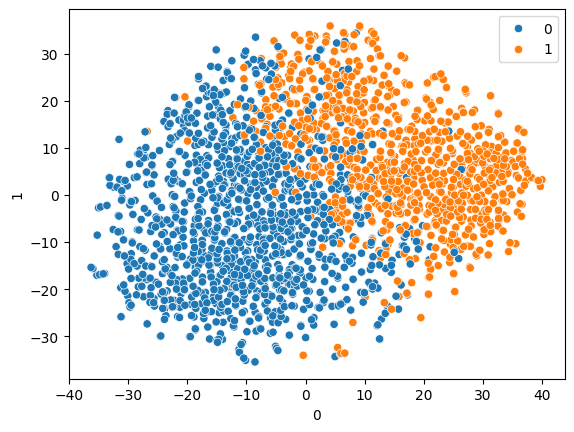

In [32]:
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

tsne = TSNE(n_components=2)
X_red = pd.DataFrame(tsne.fit_transform(X_final))
kmeans = KMeans(n_clusters=2, random_state=42)
labels = kmeans.fit_predict(X_final)

sns.scatterplot(x=X_red[0], y=X_red[1], hue=labels)
plt.show()

In [33]:
import os

def get_id(file_name):
    return int(str(file_name).split(".")[0].split("_")[1])

files = sorted(os.listdir("test_data/class_1"))
ids = [get_id(file) for file in files]
ids = sorted(ids)

ids[:20]

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

In [34]:
labels

array([0, 0, 0, ..., 1, 1, 0])

In [37]:
import pandas as pd

submission = pd.DataFrame({
    "datapointID": ids,
    "subtaskID": 1,
    "answer": labels
})
#submission.answer = submission.answer.map({0: 1, 1: 0})

submission

,datapointID,subtaskID,answer
0,0,1,0
1,1,1,0
2,2,1,0
3,3,1,0
4,4,1,1
...,...,...,...
1995,1995,1,1
1996,1996,1,0
1997,1997,1,1
1998,1998,1,1


In [38]:
submission.answer.value_counts()

answer
0    1151
1     849
Name: count, dtype: int64

In [39]:
submission.to_csv("submission.csv", index=False)